## Fråga 4: Hur ser en typisk order ut?

Vi visar det genomsnittliga ordervärdet (AOV) och hur mycket ordervärdena varierar.

In [1]:
# Med sys kan vi tala om var Python ska leta efter kod.
import sys

# Path hjälper oss att arbeta med mappar.
from pathlib import Path

# Börja i mappen där notebooken körs.
projektmapp = Path.cwd()

# Om src inte finns här, gå upp en mapp.
if not (projektmapp / "src").is_dir():
    projektmapp = projektmapp.parent

# Lägg till projektmappen så att Python kan hitta src.
sys.path.insert(0, str(projektmapp))

# Hämta gruppens klass. Datan läses in när vi skapar analysen.
from src.ecommerce import EcommerceAnalyzer

# Visa att importen lyckades.
print("Import fungerar")

Import fungerar


In [2]:
# Skapa analysen. Då läser klassen in och rensar datan.
analys = EcommerceAnalyzer()

# Hämta genomsnittligt ordervärde (AOV) och antal order.
# betyder att vi inte använder det tredje värdet här.

aov, antal_order, _ = analys.aov_and_units()

# Hämta antal sålda enheter och total intäkt.
enheter, intakt = analys.sales_totals()

# Visa genomsnittligt ordervärde, avrundat till två decimaler.
print("AOV:", round(aov, 2))

# Visa hur många order som ingår i beräkningen.
print("Antal order:", antal_order)

# Visa hur många enheter som såldes totalt.
print("Sålda enheter:", enheter)

# Visa total intäkt, avrundad till två decimaler.
print("Total intäkt:", round(intakt, 2))

# Visa hur ordervärdena varierar, till exempel minsta värde, median och största värde.
print(analys.order_value_spread())

AOV: 1401.11
Antal order: 2500
Sålda enheter: 7463
Total intäkt: 3502767.23
count    2500.000000
mean     1401.106892
std      1166.944967
min        50.000000
25%       577.960000
50%      1088.690000
75%      1884.750000
max      9192.600000
Name: revenue, dtype: float64


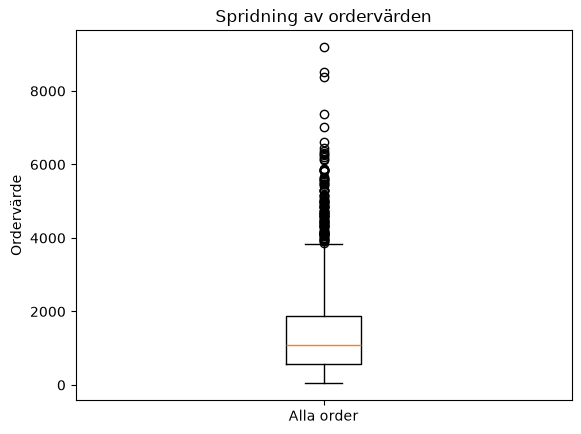

In [3]:
import matplotlib.pyplot as plt

# Hämta ordervärdena som EcommerceAnalyzer redan har läst in.
ordervarden = analys.df["revenue"]

# Rita ett låddiagram över ordervärdena.
fig, ax = plt.subplots()
ax.boxplot(ordervarden)
ax.set_title("Spridning av ordervärden")
ax.set_ylabel("Ordervärde")
ax.set_xticks([1], ["Alla order"])
plt.show()

Strecket i lådan visar medianen, som är 1 088,69. Ungefär hälften av alla order är värda mellan 577,96 och 1 884,75. Prickarna ovanför lådan visar order som är värda ovanligt mycket jämfört med de andra.

                Sammanfattning 
                
En order är värd 1 401,11 i genomsnitt (AOV). Medianen är 1 088,69. Det betyder att hälften av ordervärdena är högst 1 088,69. Några stora order höjer genomsnittet.

Ungefär hälften av ordervärdena ligger mellan 577,96 och 1 884,75. Den minsta ordern är värd 50 och den största 9 192,60.

Standardavvikelsen är 1 166,94. Den visar att ordervärdena varierar mycket.

Därför använder vi både genomsnitt, median och kvartiler för att beskriva en typisk order.